# Ожидания к датасету - grocery_and_gourmet_food

Записали пороги до того, как смотреть в данные, чтобы не подгонять их
под результат. Часть А это проверки и часть Б это гипотезы

## Часть А. Проверки

| что проверяем | порог | комментарий |
|---|---|---|
| колонки и типы | все на месте | |
| `rating` | только 1-5 | |
| `timestamp` vs партиция `year` | совпадает | |
| `helpful_vote` | >= 0 | |
| пропуски в `user_id`, `parent_asin`, `rating`, `timestamp` | 0% |  |
| полные дубли строк | 0 | |
| повторные отзывы юзера на один товар | < 1% |  |
| `parent_asin` в meta | уникален |  |
| отзывы, у которых товар есть в meta | >= 99% | |
| боты | нет | |
| пустые / короткие (< 3 слов) тексты | < 5% |  |

## Часть Б. Гипотезы

Считаем на данных после чистки по части А.

| что проверяем | ожидаем | что это даст |
|---|---|---|
| разреженность матрицы | > 99.9% | |
| юзеры с одним отзывом | > 50% |  |
| интеракции по времени | без провалов |  |
| `rating` >= 4 | >= 70% отзывов | |
| `title` у айтемов | >= 95% | |
| непустой `description` | >= 70% | |
| картинки | >= 90% | |
| контент у холодных vs тёплых | разница ≤ 10 п.п. |  |



## Подключение к S3

In [7]:
import os

import pandas as pd
import truststore

truststore.inject_into_ssl()

"AWS_ACCESS_KEY_ID" in os.environ, "AWS_SECRET_ACCESS_KEY" in os.environ

(True, True)

In [8]:
import s3fs

fs = s3fs.S3FileSystem(
    endpoint_url="https://s3.ru-7.storage.selcloud.ru",
    client_kwargs={"region_name": "ru-7"},
)
fs.ls("hse-recsys-project")

['hse-recsys-project/data']

In [9]:
for part in ["reviews", "meta"]:
    folders = fs.ls(f"hse-recsys-project/data/processed/{part}")
    print(part, [f.split("/")[-1] for f in folders])

reviews ['amazon_fashion', 'grocery_and_gourmet_food']
meta ['amazon_fashion', 'grocery_and_gourmet_food']


In [10]:
CATEGORY = "grocery_and_gourmet_food"
BASE = "hse-recsys-project/data/processed"
REVIEWS_PATH = f"{BASE}/reviews/{CATEGORY}"
META_PATH = f"{BASE}/meta/{CATEGORY}"
fs.ls(REVIEWS_PATH)

['hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/_SUCCESS',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2000',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2001',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2002',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2003',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2004',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2005',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2006',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2007',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2008',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2009',
 'hse-recsys-project/data/processed/reviews/grocery_and_gourmet_food/year=2010',
 'hse-recsys-project/data/pro

отзывы разложены по годам с 2000 по 2023

### Схема

In [ ]:
import pyarrow.dataset as ds

for kind in ["reviews", "meta"]:
    d = ds.dataset(f"{BASE}/{kind}/{CATEGORY}", filesystem=fs, partitioning="hive")
    print(kind)
    print(d.schema)
    print()

reviews
rating: int8
title: large_string
text: large_string
asin: large_string
parent_asin: large_string
user_id: large_string
timestamp: timestamp[ms]
helpful_vote: int32
verified_purchase: bool
n_images: int16
year: int32
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1337
meta
parent_asin: string
main_category: string
title: string
store: string
price: double
average_rating: double
rating_number: int64
features: list<element: string>
  child 0, element: string
description: list<element: string>
  child 0, element: string
categories: list<element: string>
  child 0, element: string
images: string
videos: string
details: string
bought_together: string
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1759


In [12]:
def schema_of(category, kind):
    path = f"{BASE}/{kind}/{category}"
    d = ds.dataset(path, filesystem=fs, partitioning="hive")
    return d.schema.remove_metadata()


for kind in ["reviews", "meta"]:
    same = schema_of(CATEGORY, kind).equals(schema_of("amazon_fashion", kind))
    print(kind, same)

reviews True
meta True


In [13]:
meta_ds = ds.dataset(META_PATH, filesystem=fs)
for field in meta_ds.schema:
    print(field.name, field.type)

parent_asin string
main_category string
title string
store string
price double
average_rating double
rating_number int64
features list<element: string>
description list<element: string>
categories list<element: string>
images string
videos string
details string
bought_together string


In [14]:
sample = meta_ds.head(3).to_pandas()
sample

,parent_asin,main_category,title,store,price,average_rating,rating_number,features,description,categories,images,videos,details,bought_together
0,B00NE08WM6,Grocery,Dark Roast Pure Coffee,Luzianne,NaN,4.7,9,[],[],"[Grocery & Gourmet Food, Beverages, Coffee]","[{""thumb"": ""https://m.media-amazon.com/images/...","[{""title"": ""YouCut_20220Cafe Du Monde Coffee C...","{""Brand"": ""Luzianne"", ""Item Form"": ""Ground"", ""...",NaN
1,B084Q13Q5Q,Grocery,PICARAS Galletas Peruanas Bañadas en Chocolate...,Winters,15.99,4.5,12,[2 Bags of PICARAS Galletas Bañadas en Chocola...,[2 Bags of PICARAS Galletas Bañadas en Chocola...,"[Grocery & Gourmet Food, Breads & Bakery, Cook...","[{""thumb"": ""https://m.media-amazon.com/images/...",[],"{""Flavor"": ""chocolate"", ""Unit Count"": ""12.00 C...",NaN
2,B00KBRUYVM,Grocery,Chipped Beef and Gravy By Patterson's - Great ...,Pattersons,NaN,3.2,5,[Six (6) 8-ounce cans of delicious chipped bee...,[Delicious corned beef gravy is ready when you...,"[Grocery & Gourmet Food, Pantry Staples, Canne...","[{""thumb"": ""https://m.media-amazon.com/images/...",[],"{""Package Dimensions"": ""8.4 x 5.8 x 3.4 inches...",NaN


In [15]:
print(sample.loc[0, "images"][:500])

[{"thumb": "https://m.media-amazon.com/images/I/51LY15EJoFL._SX38_SY50_CR,0,0,38,50_.jpg", "large": "https://m.media-amazon.com/images/I/51LY15EJoFL.jpg", "variant": "MAIN", "hi_res": "https://m.media-amazon.com/images/I/81ucKSAeinL._SL1500_.jpg"}]


images хранится как JSON-строка со списком фото, как у Fashion. на первых трех товарах categories заполнены, price пустой у товаров с индексами 0 из 2, у одного товара пустые features и description, bought_together пустой у всех трех

### Загрузка отзывов

In [16]:
reviews_ds = ds.dataset(REVIEWS_PATH, filesystem=fs, partitioning="hive")

cols = [
    "user_id",
    "parent_asin",
    "asin",
    "rating",
    "timestamp",
    "helpful_vote",
    "verified_purchase",
    "n_images",
    "year",
]

reviews = reviews_ds.to_table(columns=cols).to_pandas()
reviews.shape

(14318520, 9)

In [17]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 14318520 entries, 0 to 14318519
Data columns (total 9 columns):
 #   Column             Dtype         
---  ------             -----         
 0   user_id            str           
 1   parent_asin        str           
 2   asin               str           
 3   rating             int8          
 4   timestamp          datetime64[ms]
 5   helpful_vote       int32         
 6   verified_purchase  bool          
 7   n_images           int16         
 8   year               int32         
dtypes: bool(1), datetime64[ms](1), int16(1), int32(2), int8(1), str(3)
memory usage: 1.2 GB


## Часть А. проверки 

### Пропуски

In [18]:
reviews.isna().sum()

user_id              0
parent_asin          0
asin                 0
rating               0
timestamp            0
helpful_vote         0
verified_purchase    0
n_images             0
year                 0
dtype: int64

### Значения

In [19]:
results = []


def expect(name, fact, ok, comment=""):
    results.append({"проверка": name, "факт": fact, "ok": ok, "комментарий": comment})

In [20]:
schema_ok = all(
    schema_of(CATEGORY, k).equals(schema_of("amazon_fashion", k))
    for k in ["reviews", "meta"]
)
expect("колонки и типы как у Fashion", schema_ok, schema_ok)

key_cols = ["user_id", "parent_asin", "rating", "timestamp"]
n_missing = int(reviews[key_cols].isna().sum().sum())
n_empty_ids = int(
    (reviews["user_id"] == "").sum() + (reviews["parent_asin"] == "").sum()
)
expect(
    "пропуски в ключевых колонках",
    n_missing + n_empty_ids,
    n_missing + n_empty_ids == 0,
)

bad_rating = int((~reviews["rating"].between(1, 5)).sum())
expect("rating только 1-5", bad_rating, bad_rating == 0)

year_mismatch = int((reviews["timestamp"].dt.year != reviews["year"]).sum())
expect("timestamp совпадает с year", year_mismatch, year_mismatch == 0)

neg_votes = int((reviews["helpful_vote"] < 0).sum())
expect("helpful_vote >= 0", neg_votes, neg_votes == 0)

pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,колонки и типы как у Fashion,True,True,
1,пропуски в ключевых колонках,0,True,
2,rating только 1-5,1,False,
3,timestamp совпадает с year,0,True,
4,helpful_vote >= 0,1,False,


In [21]:
bad_rows = reviews[~reviews["rating"].between(1, 5) | (reviews["helpful_vote"] < 0)]
bad_rows

,user_id,parent_asin,asin,rating,timestamp,helpful_vote,verified_purchase,n_images,year
7026041,AGFL57VKXAMV33AOCIWIRTFHGNPA,B0C396H8QB,B00RQPUV0Q,0,2020-07-25 19:06:23.161,0,True,0,2020
11811296,AGD6I6K6VVPPNL3FNK4BXYTYZCHQ,B0C8X7LRZL,B08P39M3LN,5,2022-08-12 08:45:45.231,-1,True,0,2022


две проверки не прошли, но в каждой ровно по одной строке, и это разные отзывы: у одного rating = 0 (на Amazon оценки только от 1 до 5), у другого helpful_vote = -1. это ошибки в данных, 2 строки из 14.3 млн, поэтому удаляем их и дальше работаем без них

In [22]:
ok_mask = reviews["rating"].between(1, 5) & (reviews["helpful_vote"] >= 0)
reviews = reviews[ok_mask]
len(reviews)

14318518

схема такая же, как у Fashion, пропусков в ключевых колонках нет, даты совпадают с партициями. две проверки не прошли, но в каждой ровно по одной строке, и это разные отзывы: у одного rating = 0 (на Amazon оценки только от 1 до 5), у другого helpful_vote = -1. это ошибки в данных, 2 строки из 14.3 млн, поэтому удаляем их и дальше работаем без них

### Дубликаты 

In [23]:
n_full_dup = int(reviews.duplicated().sum())
expect("полные дубли строк", n_full_dup, n_full_dup == 0, "сравнивали без title и text")

repeat_share = reviews.duplicated(["user_id", "parent_asin"]).mean()
expect("повторные отзывы юзера на товар", f"{repeat_share:.2%}", repeat_share < 0.01)

pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,колонки и типы как у Fashion,True,True,
1,пропуски в ключевых колонках,0,True,
2,rating только 1-5,1,False,
3,timestamp совпадает с year,0,True,
4,helpful_vote >= 0,1,False,
5,полные дубли строк,130928,False,сравнивали без title и text
6,повторные отзывы юзера на товар,1.66%,False,


In [24]:
dedup = reviews.drop_duplicates()
real_repeat_share = dedup.duplicated(["user_id", "parent_asin"]).mean()
print(len(dedup), f"{real_repeat_share:.2%}")

14187590 0.75%


In [26]:
rep = dedup[dedup.duplicated(["user_id", "parent_asin"], keep=False)]
same_asin = rep.duplicated(["user_id", "parent_asin", "asin"], keep=False).mean()
print(len(rep), f"{same_asin:.2%}")

201255 0.03%


In [ ]:
expect(
    "повторы после удаления дублей",
    f"{real_repeat_share:.2%}",
    real_repeat_share < 0.01,
    "оставляем, 99.97% это отзывы на разные варианты товаров",
)
reviews_clean = dedup
pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,колонки и типы как у Fashion,True,True,
1,пропуски в ключевых колонках,0,True,
2,rating только 1-5,1,False,
3,timestamp совпадает с year,0,True,
4,helpful_vote >= 0,1,False,
5,полные дубли строк,130928,False,сравнивали без title и text
6,повторные отзывы юзера на товар,1.66%,False,
7,повторы после удаления дублей,0.75%,True,"оставляем, 99,97% это отзывы на разные вариант..."


полных дублей 130 928 (0.91% отзывов), это технические копии, удаляем. после этого осталось 14 187 590 отзывов. повторных отзывов юзера на тот же товар 0.75%, и почти все (99.97%) это отзывы на разные варианты товара, а не переписанный отзыв на тот же вариант, поэтому их оставляем

### Связь с каталогом 

In [30]:
meta_ids = meta_ds.to_table(columns=["parent_asin"]).to_pandas()

n_meta_dup = int(meta_ids["parent_asin"].duplicated().sum())
expect(
    "parent_asin в meta уникален",
    n_meta_dup,
    n_meta_dup == 0,
    "каждый товар один раз в каталоге",
)

in_meta_share = reviews_clean["parent_asin"].isin(meta_ids["parent_asin"]).mean()
expect("товар отзыва есть в meta", f"{in_meta_share:.2%}", in_meta_share >= 0.99)

pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,колонки и типы как у Fashion,True,True,
1,пропуски в ключевых колонках,0,True,
2,rating только 1-5,1,False,
3,timestamp совпадает с year,0,True,
4,helpful_vote >= 0,1,False,
5,полные дубли строк,130928,False,сравнивали без title и text
6,повторные отзывы юзера на товар,1.66%,False,
7,повторы после удаления дублей,0.75%,True,"оставляем, 99,97% это отзывы на разные вариант..."
8,parent_asin в meta уникален,0,True,каждый товар один раз в каталоге
9,товар отзыва есть в meta,100.00%,True,


каталог чистый: каждый parent_asin в meta встречается один раз, товар из отзыва есть в meta у 100.00% отзывов

### Боты 

In [31]:
per_user = reviews_clean.groupby("user_id").size()
per_user.describe(percentiles=[0.5, 0.9, 0.99, 0.999])

count    7.034392e+06
mean     2.016889e+00
std      4.223647e+00
min      1.000000e+00
50%      1.000000e+00
90%      4.000000e+00
99%      1.400000e+01
99.9%    4.300000e+01
max      1.524000e+03
dtype: float64

In [32]:
same_moment = reviews_clean.groupby(["user_id", "timestamp"]).size()
same_moment.value_counts().sort_index()

1    14187229
2         175
3           1
4           2
Name: count, dtype: int64

In [33]:
top_users = per_user.nlargest(10).index

(
    reviews_clean[reviews_clean["user_id"].isin(top_users)]
    .groupby("user_id")["timestamp"]
    .agg(["count", "min", "max"])
    .sort_values("count", ascending=False)
)

,count,min,max
user_id,,,
AF2BLE54TEMGZ546U763ZHZRXC4A,1524,2013-07-10 16:32:30.000,2023-03-15 13:14:30.404
AGXNNDGBBN7K2RJQQW7UBR347SZA,1413,2007-11-24 04:08:20.000,2023-04-06 01:56:46.544
AECIT3NMW6RKABFS6YOCYX4YUYOQ,1375,2020-07-26 23:15:15.152,2023-03-25 20:32:53.748
AEAXAJACFMXIAAH4WOHRMXPSZWFA,1314,2006-03-22 18:12:57.000,2023-03-17 01:20:47.751
AG63W2BMC4HRP76AMS36AYY64AHA,1309,2007-08-14 18:56:57.000,2023-03-15 01:52:50.468
AFSHXT5PTGDSFW2725SDXIE6ZVEA,1124,2010-04-12 16:12:09.000,2023-03-31 01:53:41.239
AEHMQSTB6ESWFAT4AHROTV6M7VWA,954,2019-04-02 16:28:31.193,2023-03-10 03:35:46.718
AGXZJUBKMLQLK5B7TSAVA7TONKVQ,849,2019-07-25 20:17:22.297,2023-03-05 21:14:25.097
AGWDYYVVWM3DC3CASUZKXK67G6IA,835,2003-10-16 10:30:16.000,2023-03-14 02:12:25.941


In [34]:
expect(
    "боты", "не найдены", True, "нет пачек в один момент; самые активные пишут годами"
)
pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,колонки и типы как у Fashion,True,True,
1,пропуски в ключевых колонках,0,True,
2,rating только 1-5,1,False,
3,timestamp совпадает с year,0,True,
4,helpful_vote >= 0,1,False,
5,полные дубли строк,130928,False,сравнивали без title и text
6,повторные отзывы юзера на товар,1.66%,False,
7,повторы после удаления дублей,0.75%,True,"оставляем, 99,97% это отзывы на разные вариант..."
8,parent_asin в meta уникален,0,True,каждый товар один раз в каталоге
9,товар отзыва есть в meta,100.00%,True,


ботов не нашли. медиана 1 отзыв на юзера, у 99% юзеров не больше 14 отзывов, максимум 1 524. одновременных пачек почти нет: всего 178 моментов, когда у юзера 2-4 отзыва в одну миллисекунду, похоже на оценку нескольких вариантов товара разом. у топ-10 активных юзеров первый и последний отзыв разделяют от 2.7 до 19.5 лет, то есть они пишут годами, а не пачкой за день

### Короткие тексты 

In [35]:
texts = reviews_ds.to_table(
    columns=["user_id", "parent_asin", "timestamp", "text"]
).to_pandas()
texts = texts.drop_duplicates(subset=["user_id", "parent_asin", "timestamp"])

n_words = texts["text"].str.split().str.len()
short_share = (n_words.fillna(0) < 3).mean()
expect("пустые / короткие (< 3 слов) тексты", f"{short_share:.2%}", short_share < 0.05)
pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,колонки и типы как у Fashion,True,True,
1,пропуски в ключевых колонках,0,True,
2,rating только 1-5,1,False,
3,timestamp совпадает с year,0,True,
4,helpful_vote >= 0,1,False,
5,полные дубли строк,130928,False,сравнивали без title и text
6,повторные отзывы юзера на товар,1.66%,False,
7,повторы после удаления дублей,0.75%,True,"оставляем, 99,97% это отзывы на разные вариант..."
8,parent_asin в meta уникален,0,True,каждый товар один раз в каталоге
9,товар отзыва есть в meta,100.00%,True,


In [36]:
texts.loc[n_words < 3, "text"].sample(15, random_state=42)

10367363               Disgusting.
9148637                       good
14291551                          
12733286               Flavorless.
12218145                    Price.
10276378              Fresh flavor
8378382          Excellent flavor!
7202651       Beautiful packaging.
696530                        Good
14311571                        Ok
5835528                 It's okay.
2656365                Wonderful !
1557070                 Thank you!
2418124                      Salty
1676167     Dangerously delicious.
Name: text, dtype: str

In [37]:
n_empty = int((n_words.fillna(0) == 0).sum())
print(n_empty, f"{n_empty / len(texts):.2%}")

16578 0.12%


In [38]:
expect(
    "решение по коротким текстам",
    "оставляем",
    True,
    "короткие отзывы осмысленные, взаимодействие настоящее",
)
del texts
pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,колонки и типы как у Fashion,True,True,
1,пропуски в ключевых колонках,0,True,
2,rating только 1-5,1,False,
3,timestamp совпадает с year,0,True,
4,helpful_vote >= 0,1,False,
5,полные дубли строк,130928,False,сравнивали без title и text
6,повторные отзывы юзера на товар,1.66%,False,
7,повторы после удаления дублей,0.75%,True,"оставляем, 99,97% это отзывы на разные вариант..."
8,parent_asin в meta уникален,0,True,каждый товар один раз в каталоге
9,товар отзыва есть в meta,100.00%,True,


коротких текстов (меньше 3 слов) 8.54%, порог 5% не прошли. но в случайной выборке из 15 штук почти все это нормальные лаконичные отзывы вроде "Salty", "Excellent flavor!", "Disgusting.". совсем пустых всего 16 578 (0.12%)

## Итог части А

данные Grocery в хорошем состоянии: схема как у Fashion, пропусков нет, ботов не нашли, у всех отзывов есть карточка товара в каталоге

что делаем в ETL: удаляем 2 строки с ошибками (rating = 0 и helpful_vote = -1) и 130 928 полных дублей (0.91%). остальное оставляем как есть. после чистки 14 187 590 отзывов

## Часть Б. Гипотезы по grocery

In [39]:
print(reviews_clean.shape)
reviews_clean.head(3)

(14187590, 9)


,user_id,parent_asin,asin,rating,timestamp,helpful_vote,verified_purchase,n_images,year
0,AHG34BLPBFJAZLKSZTRSVPBYMNQA,B07CKJHCYK,B00004S1C6,5,2000-08-09 11:28:21,28,False,0,2000
1,AHG34BLPBFJAZLKSZTRSVPBYMNQA,B00004S1C5,B00004S1C5,5,2000-08-09 11:26:35,9,False,0,2000
2,AHZ4COF4GITWBEDDWARFGMFGJ7YA,B00004S1C5,B00004S1C5,5,2000-12-06 02:12:46,31,False,0,2000


### Разреженность

In [40]:
n_users = reviews_clean["user_id"].nunique()
n_items = reviews_clean["parent_asin"].nunique()
print(f"юзеров: {n_users:,}, товаров: {n_items:,}")

юзеров: 7,034,392, товаров: 603,182


In [41]:
pairs = reviews_clean[["user_id", "parent_asin"]].drop_duplicates()
n_pairs = len(pairs)

density = n_pairs / (n_users * n_items)
sparsity = 1 - density

print(f"уникальных пар: {n_pairs:,}")
print(f"плотность: {density:.2e}, разреженность: {sparsity:.5%}")

уникальных пар: 14,081,168
плотность: 3.32e-06, разреженность: 99.99967%


In [42]:
expect(
    "разреженность матрицы > 99.9%",
    f"{sparsity:.5%}",
    sparsity > 0.999,
    "3.3 клетки на млн (у Fashion 1.5), пересечений между юзерами почти нет",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
11,пустые / короткие (< 3 слов) тексты,8.54%,False,
12,решение по коротким текстам,оставляем,True,"короткие отзывы осмысленные, взаимодействие на..."
13,разреженность матрицы > 99.9%,99.99967%,True,"3.3 клетки на млн (у Fashion 1.5), пересечений..."


юзеров 7 034 392, товаров 603 182, уникальных пар юзер-товар 14 081 168. разреженность 99.99967%, то есть заполнено 3.3 клетки на миллион. это примерно в 2 раза плотнее, чем у Fashion (1.5 на миллион), но матрица все равно очень пустая

### Юзеры с одним отзывом

In [43]:
user_cnt = pairs.groupby("user_id").size()
user_cnt.head()

user_id
AE2222LOSPU74RGYRMV6CVRTTHZQ    1
AE2222M5T6IMPZWTCOJS54O73JXA    1
AE2222VGHFD37G7NOCWXASYY3ZDQ    2
AE22232OB6S7UAC75JUFYRGBSHIQ    2
AE22236AFRRSMQIKGG7TPTB75QEA    6
dtype: int64

In [44]:
share_users_1 = (user_cnt == 1).mean()
print(f"юзеров с одним товаром: {share_users_1:.1%}")

юзеров с одним товаром: 66.5%


In [45]:
user_cnt.value_counts().sort_index().head(10)

1     4680824
2     1172472
3      466781
4      234531
5      134579
6       85172
7       56930
8       40506
9       29182
10      22268
Name: count, dtype: int64

In [46]:
active = user_cnt >= 5
print(f"юзеров с 5+ товарами: {active.sum():,} ({active.mean():.2%})")
print(f"максимум у одного юзера: {user_cnt.max()}")

юзеров с 5+ товарами: 479,784 (6.82%)
максимум у одного юзера: 1432


In [47]:
expect(
    "юзеры с одним отзывом > 50%",
    f"{share_users_1:.1%}",
    share_users_1 > 0.5,
    "5+ товаров только у 6.82% юзеров (479.8 тыс.), максимум 1432",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
12,решение по коротким текстам,оставляем,True,"короткие отзывы осмысленные, взаимодействие на..."
13,разреженность матрицы > 99.9%,99.99967%,True,"3.3 клетки на млн (у Fashion 1.5), пересечений..."
14,юзеры с одним отзывом > 50%,66.5%,True,"5+ товаров только у 6.82% юзеров (479.8 тыс.),..."


у 66.5% юзеров один товар (у Fashion было 86.2%), гипотеза > 50% подтвердилась. 5+ товаров у 479 784 юзеров (6.82%), это больше чем у Fashion. максимум 1 432 разных товара у одного юзера. для Grocery фильтр 5-core выглядит реальным: кандидатов около 480 тыс. юзеров

### Интеракции по времени

In [48]:
by_year = reviews_clean.groupby(reviews_clean["timestamp"].dt.year).size()
by_year

timestamp
2000          5
2001          8
2002         21
2003         58
2004        230
2005        654
2006       3782
2007      11615
2008      15720
2009      25448
2010      39865
2011      70016
2012     119815
2013     313276
2014     516833
2015     789711
2016     946555
2017     992934
2018    1175687
2019    1659771
2020    2242166
2021    2364352
2022    2130562
2023     768506
dtype: int64

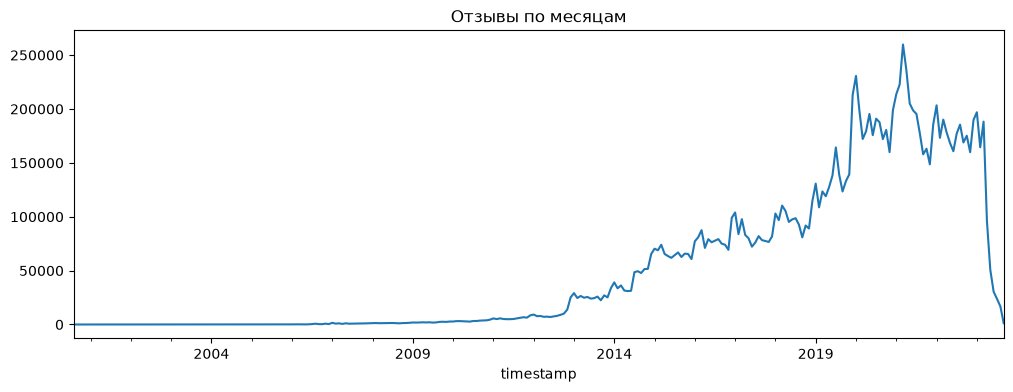

In [49]:
month = reviews_clean["timestamp"].dt.to_period("M")
by_month = reviews_clean.groupby(month).size()
by_month.plot(figsize=(12, 4), title="Отзывы по месяцам");

In [50]:
by_month["2019-01":"2021-06"]

timestamp
2019-01    130729
2019-02    108685
2019-03    123470
2019-04    119008
2019-05    127619
2019-06    138360
2019-07    164282
2019-08    138977
2019-09    123451
2019-10    133049
2019-11    139254
2019-12    212887
2020-01    230668
2020-02    198831
2020-03    172171
2020-04    179259
2020-05    195383
2020-06    175678
2020-07    191012
2020-08    187726
2020-09    172027
2020-10    180537
2020-11    159950
2020-12    198924
2021-01    213729
2021-02    222586
2021-03    259821
2021-04    236150
2021-05    205056
2021-06    198685
Freq: M, dtype: int64

In [51]:
main = by_month["2015-01":"2022-12"]
drops = main.pct_change()
drops.nsmallest(3)

timestamp
2017-02   -0.193395
2016-04   -0.188233
2019-02   -0.168624
Freq: M, dtype: float64

In [ ]:
worst = drops.min()
no_gaps = len(main) == 8 * 12
print(f"месяцев в периоде: {len(main)}, самое сильное падение: {worst:.1%}")

expect(
    "интеракции по времени без провалов",
    f"{worst:.1%}",
    worst > -0.5 and no_gaps,
    "2015-2022 без пропусков; худшее -19.3% в 02.2017, COVID-ямы нет",
)
pd.DataFrame(results).tail(3)

месяцев в периоде: 96, самое сильное падение: -19.3%


,проверка,факт,ok,комментарий
13,разреженность матрицы > 99.9%,99.99967%,True,"3.3 клетки на млн (у Fashion 1.5), пересечений..."
14,юзеры с одним отзывом > 50%,66.5%,True,"5+ товаров только у 6.82% юзеров (479.8 тыс.),..."
15,интеракции по времени без провалов,-19.3%,True,2015-2022 без пропусков; худшее -19.3 в 02.201...


по месяцам без провалов: в 2015-2022 все 96 месяцев есть, самые сильные падения -19.3% (февраль 2017), -18.8% (апрель 2016) и -16.9% (февраль 2019). два из трех в феврале, похоже на сезонность: в феврале меньше дней, а перед ним пик января. в отличие от Fashion, ямы весной 2020 нет: в марте 2020 отзывов меньше, чем в феврале, но уже с мая снова рост, а пик пришелся на 2021. до 2015 данных мало, но больше, чем у Fashion: 7.9% отзывов, в основном 2013-2014. 2023 неполный

### rating >= 4

In [53]:
rating_share = reviews_clean["rating"].value_counts(normalize=True).sort_index()
rating_share

rating
1    0.129274
2    0.048562
3    0.062768
4    0.087836
5    0.671560
Name: proportion, dtype: float64

In [54]:
share_pos = (reviews_clean["rating"] >= 4).mean()
print(f"rating >= 4: {share_pos:.1%}")

rating >= 4: 75.9%


In [55]:
expect(
    "rating >= 4 у >= 70% отзывов",
    f"{share_pos:.1%}",
    share_pos >= 0.7,
    "с запасом; пятерок 67%, единиц 13%, больше чем двоек и троек вместе",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
14,юзеры с одним отзывом > 50%,66.5%,True,"5+ товаров только у 6.82% юзеров (479.8 тыс.),..."
15,интеракции по времени без провалов,-19.3%,True,2015-2022 без пропусков; худшее -19.3 в 02.201...
16,rating >= 4 у >= 70% отзывов,75.9%,True,"с запасом; пятерок 67%, единиц 13%, больше чем..."


rating >= 4 у 75.9% отзывов, гипотеза >= 70% подтвердилась с запасом (у Fashion было 71.1%, впритык). распределение перекошено к краям: пятерок 67.2%, единиц 12.9%, а двоек (4.9%) и троек (6.3%) вместе меньше, чем единиц. люди в основном ставят либо 5, либо 1

### Контент товаров

In [56]:
meta = (
    ds.dataset(META_PATH, filesystem=fs)
    .to_table(columns=["parent_asin", "title", "description", "features", "images"])
    .to_pandas()
)
meta.shape

(603274, 5)

In [57]:
meta.head(3)

,parent_asin,title,description,features,images
0,B00NE08WM6,Dark Roast Pure Coffee,[],[],"[{""thumb"": ""https://m.media-amazon.com/images/..."
1,B084Q13Q5Q,PICARAS Galletas Peruanas Bañadas en Chocolate...,[2 Bags of PICARAS Galletas Bañadas en Chocola...,[2 Bags of PICARAS Galletas Bañadas en Chocola...,"[{""thumb"": ""https://m.media-amazon.com/images/..."
2,B00KBRUYVM,Chipped Beef and Gravy By Patterson's - Great ...,[Delicious corned beef gravy is ready when you...,[Six (6) 8-ounce cans of delicious chipped bee...,"[{""thumb"": ""https://m.media-amazon.com/images/..."


In [58]:
has_title = meta["title"].notna() & (meta["title"].str.strip() != "")
print(f"title есть: {has_title.mean():.1%}")

title есть: 100.0%


In [59]:
(~has_title).sum()

38

In [60]:
expect(
    "title у айтемов >= 95%",
    f"{has_title.mean():.2%}",
    has_title.mean() >= 0.95,
    "без title всего 38 товаров",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
15,интеракции по времени без провалов,-19.3%,True,2015-2022 без пропусков; худшее -19.3 в 02.201...
16,rating >= 4 у >= 70% отзывов,75.9%,True,"с запасом; пятерок 67%, единиц 13%, больше чем..."
17,title у айтемов >= 95%,99.99%,True,без title всего 38 товаров


title есть у 99.99% товаров, без названия всего 38 из 603 274. гипотеза >= 95% подтвердилась

In [61]:
desc_text = meta["description"].str.join(" ").fillna("").str.strip()
has_desc = desc_text != ""

n_no_desc = (~has_desc).sum()
print(f"description есть: {has_desc.mean():.1%}, без description: {n_no_desc:,}")

description есть: 62.7%, без description: 225,223


In [62]:
print((meta["description"].str.len() > 0).mean())
desc_text[has_desc].head(3)

0.6266654952807513


1    2 Bags of PICARAS Galletas Bañadas en Chocolat...
2    Delicious corned beef gravy is ready when you ...
5    Crystal Light Peach Tea is a peach flavored ic...
Name: description, dtype: object

In [63]:
expect(
    "непустой description >= 70%",
    f"{has_desc.mean():.1%}",
    has_desc.mean() >= 0.7,
    "62.7%, без description 225 тыс. (у Fashion 7.2%)",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
16,rating >= 4 у >= 70% отзывов,75.9%,True,"с запасом; пятерок 67%, единиц 13%, больше чем..."
17,title у айтемов >= 95%,99.99%,True,без title всего 38 товаров
18,непустой description >= 70%,62.7%,False,"62.7%, без description 225 тыс. (у Fashion 7.2%)"


description есть у 62.7% товаров (без него 225 223), порог 70% не прошли. но это намного лучше, чем у Fashion (7.2%): у еды обычно описывают вкус, состав и упаковку. доля непустых списков тоже 62.7%, то есть списков с одними пустыми строками практически нет

In [64]:
feat_text = meta["features"].str.join(" ").fillna("").str.strip()
has_feat = feat_text != ""
print(f"features есть: {has_feat.mean():.1%}")
print(f"есть description или features: {(has_desc | has_feat).mean():.1%}")

features есть: 72.2%
есть description или features: 78.5%


features есть у 72.2% товаров (у Fashion 56.1%)

In [65]:
meta["images"].value_counts().head(3)

images
[{"thumb": "https://m.media-amazon.com/images/I/01RmK+J4pJL._SX38_SY50_CR,0,0,38,50_.gif", "large": "https://m.media-amazon.com/images/I/01RmK+J4pJL.gif", "variant": "MAIN", "hi_res": null}]                                                              1686
[{"thumb": "https://m.media-amazon.com/images/I/01RmK+J4pJL._AC_US40_.gif", "large": "https://m.media-amazon.com/images/I/01RmK+J4pJL._AC_.gif", "variant": "MAIN", "hi_res": null}]                                                                         218
[{"thumb": "https://m.media-amazon.com/images/I/41Fv1CNwCkL._SX38_SY50_CR,0,0,38,50_.jpg", "large": "https://m.media-amazon.com/images/I/41Fv1CNwCkL.jpg", "variant": "MAIN", "hi_res": "https://m.media-amazon.com/images/I/51m1gdQJW2L._SL1000_.jpg"}]     179
Name: count, dtype: int64

In [66]:
top = meta["images"].value_counts()
print(top.head(3).values)
print("пустых []:", (meta["images"] == "[]").sum())
print("null:", meta["images"].isna().sum())

[1686  218  179]
пустых []: 88
null: 0


In [68]:
placeholder = meta["images"].str.contains("01RmK+J4pJL", regex=False)
has_img = (meta["images"] != "[]") & ~placeholder
print(f"с заглушкой: {placeholder.sum():,}")
print(f"картинки есть: {has_img.mean():.1%}")

с заглушкой: 1,977
картинки есть: 99.7%


In [ ]:
expect(
    "картинки >= 90%",
    f"{has_img.mean():.1%}",
    has_img.mean() >= 0.9,
    "1 977 товаров с картинкой-заглушкой, считаем их без фото",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
17,title у айтемов >= 95%,99.99%,True,без title всего 38 товаров
18,непустой description >= 70%,62.7%,False,"62.7%, без description 225 тыс. (у Fashion 7.2%)"
19,картинки >= 90%,99.7%,True,"1 977 товара с картинкой-заглушкой, считаем их..."


картинки есть у 99.7% товаров, гипотеза >= 90% подтвердилась. заглушка та же, что у Fashion (gif с кодом 01RmK+J4pJL), она у 1 977 товаров, плюс 88 товаров с пустым списком, всех их считаем без фото

### Холодные vs теплые товары 

In [70]:
item_cnt = pairs.groupby("parent_asin").size()
meta["n_users"] = meta["parent_asin"].map(item_cnt).fillna(0)
is_warm = meta["n_users"] >= 5
print(f"тёплых товаров: {is_warm.sum():,} ({is_warm.mean():.1%})")

тёплых товаров: 259,082 (42.9%)


In [71]:
content = pd.DataFrame(
    {
        "title": has_title,
        "description": has_desc,
        "features": has_feat,
        "картинки": has_img,
    }
)
cmp = content.groupby(is_warm).mean() * 100
cmp.index = ["холодные", "тёплые"]
cmp.round(1)

,title,description,features,картинки
холодные,100.0,60.9,67.0,99.5
тёплые,100.0,65.0,79.3,99.9


In [72]:
diff = cmp.loc["тёплые"] - cmp.loc["холодные"]
max_diff = diff.abs().max()
print(diff.round(1))

title          -0.0
description     4.0
features       12.3
картинки        0.4
dtype: double[pyarrow]


In [73]:
expect(
    "контент у холодных vs тёплых: разница <= 10 п.п.",
    f"{max_diff:.1f} п.п.",
    max_diff <= 10,
    "больше всего отстают features (67% против 79%); тёплый = 5+ юзеров",
)
pd.DataFrame(results).tail(3)

,проверка,факт,ok,комментарий
18,непустой description >= 70%,62.7%,False,"62.7%, без description 225 тыс. (у Fashion 7.2%)"
19,картинки >= 90%,99.7%,True,"1 977 товара с картинкой-заглушкой, считаем их..."
20,контент у холодных vs тёплых: разница <= 10 п.п.,12.3 п.п.,False,больше всего отстают features (67% против 79%)...


теплых товаров (5+ юзеров) 259 082, это 42.9% каталога, у Fashion было всего 11.3%. контент у холодных хуже, чем у теплых, сильнее всего по features. по остальным разница маленькая: description 60.9% против 65.0% (4 п.п.), картинки 99.5% против 99.9%, title у всех 100%. для холодных товаров контентные признаки все равно есть: название у всех, картинки почти у всех, features у двух третей

In [74]:
pd.DataFrame(results)

,проверка,факт,ok,комментарий
0,колонки и типы как у Fashion,True,True,
1,пропуски в ключевых колонках,0,True,
2,rating только 1-5,1,False,
3,timestamp совпадает с year,0,True,
4,helpful_vote >= 0,1,False,
5,полные дубли строк,130928,False,сравнивали без title и text
6,повторные отзывы юзера на товар,1.66%,False,
7,повторы после удаления дублей,0.75%,True,"оставляем, 99,97% это отзывы на разные вариант..."
8,parent_asin в meta уникален,0,True,каждый товар один раз в каталоге
9,товар отзыва есть в meta,100.00%,True,


## Итог части Б

по взаимодействиям: матрица очень разреженная (99.99967%), но примерно в 2 раза плотнее, чем у Fashion. один товар у 66.5% юзеров (у Fashion 86.2%), 5+ товаров у 6.82% юзеров, это 479 784 человека (у Fashion 0.72%). в 2015-2022 отзывы есть за все 96 месяцев, ямы весной 2020 нет, самые сильные падения сезонные, до -19.3% в феврале 2017. rating >= 4 у 75.9%, оценки в основном 5 (67.2%) или 1 (12.9%).

по контенту: title у 99.99% товаров, картинки у 99.7%, features у 72.2%, description у 62.7%, хоть какой-то текст кроме названия у 78.5%. теплых товаров (5+ юзеров) 42.9% каталога. контент у холодных хуже всего по features: 67.0% против 79.3% у теплых

не подтвердились две гипотезы: description (62.7% при пороге 70%) и разница контента холодных и теплых (12.3 п.п. при пороге 10). остальные подтвердились, а по длине историй юзеров и доле теплых товаров Grocery намного богаче Fashion

In [77]:
from pathlib import Path

out = Path("../reports")
out.mkdir(exist_ok=True)
pd.DataFrame(results).to_csv(out / f"eda_{CATEGORY}.csv", index=False)